# Nhận dạng giới tính bằng CNN + MLP (PyTorch)

Bản PyTorch của `Yêu cầu/examples/2. CNN + MLP/2_Human_Gender_CNN.ipynb`, giữ nguyên thứ tự mục và cấu hình của gốc.

- Dữ liệu WIKI: ảnh mặt người xám 64×64, nhãn female/male (one-hot, cột 0 = female, cột 1 = male).
- Mô hình: 5 khối conv 3×3 same (16×2, 32×3, 64×3, 128×3, 256×3), mỗi khối MaxPool 2×2 + Dropout 0.2 → FC 1024 → FC 1024 → FC 2.
- Huấn luyện: `categorical_crossentropy`, Adam lr 1e-4, batch 128, 30 epoch; validation là tập val (gọi là test như gốc).

| | Keras gốc (Keras 2.0.9, GTX 1080) | PyTorch |
|---|---|---|
| Số tham số | 4.063.570 | kiểm bằng `assert` ở mục (2) |
| Test accuracy | 0.8264 | xem mục (4) |
| Test loss | 0.4602 | xem mục (4) |

**Lưu ý khi đọc kết quả** (đã kiểm dữ liệu 23/11): 78,85% ảnh là male ở cả train và val, nên đoán toàn "male" đã được 0.7885 (đúng bằng `val_acc` epoch 1 của log gốc). 662/5968 ảnh val đen hoàn toàn. Giữ nguyên dữ liệu để so sánh công bằng với gốc; phần cuối notebook có tính thêm recall từng lớp.

# Import libraries

Keras gốc:
```python
import keras
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.optimizers import Adam
```

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # để import pytorch/common.py
from common import *

import torch.nn.functional as F
from collections import OrderedDict
import matplotlib.pyplot as plt

# True: chỉ chạy thử (ít dữ liệu, 1 epoch) để kiểm code trên CPU; bản nộp phải là False (chạy GPU)
CHAY_THU = False

set_seed(0)
device = get_device()

torch 2.11.0+cu130 | thiết bị: cuda (Tesla T4)


In [2]:
num_classes = 2   # male vs. female
TEN = "2_Human_Gender_CNN"

# (1) Data

Keras gốc:
```python
x_train = np.load('64_64_11938_4098_train_x_onehot.npy')
y_train = np.load('64_64_11938_4098_train_y_onehot.npy')
x_train = np.rot90(x_train, k=3, axes=(1, 2))
x_test = np.load('64_64_5968_4098_val_x_onehot.npy')
y_test = np.load('64_64_5968_4098_val_y_onehot.npy')
x_test = np.rot90(x_test, k=3, axes=(1, 2))
```

Khác Keras:
- Đọc từ `data/gender/` (git bỏ qua; trên Colab/Kaggle chép 4 file vào đó).
- Giữ `np.rot90(k=3)` (ảnh lưu bị xoay) và **không chia 255** như gốc: ảnh đưa vào mạng có giá trị 0–255.
- `to_nchw`: `(N, 64, 64, 1)` → `(N, 1, 64, 64)`, đổi float64 → float32 (PyTorch mặc định float32; Keras cũng tự ép về float32).
- Nhãn one-hot → chỉ số lớp cho `nn.CrossEntropyLoss`.
- `mmap_mode='r'` để khi chạy thử chỉ đọc phần cần dùng (file train 391 MB).
- Dữ liệu **xếp theo nhãn**: male trước, female sau (train: vị trí 0–9412 male, 9413–11937 female; val tương tự). `DataLoader(shuffle=True)` xáo lại mỗi epoch, như `fit` của Keras mặc định `shuffle=True`, nên không ảnh hưởng huấn luyện.

In [3]:
def doc_gender(ten_x, ten_y, n=None):
    x = np.load(DATA_DIR / "gender" / ten_x, mmap_mode="r")
    y = np.load(DATA_DIR / "gender" / ten_y)
    if n is not None:                            # chạy thử: lấy rải đều cả file vì dữ liệu xếp male trước, female sau
        buoc = len(y) // n
        x, y = x[::buoc][:n], y[::buoc][:n]
    x = np.rot90(x, k=3, axes=(1, 2))           # như gốc
    return to_nchw(x), onehot_to_index(y)      # (N, 1, 64, 64) float32 0–255, nhãn 0/1

n = 1000 if CHAY_THU else None
x_train, y_train = doc_gender('64_64_11938_4098_train_x_onehot.npy', '64_64_11938_4098_train_y_onehot.npy', n)
x_test, y_test = doc_gender('64_64_5968_4098_val_x_onehot.npy', '64_64_5968_4098_val_y_onehot.npy', n)

print(tuple(x_train.shape), tuple(x_test.shape), "| giá trị %.0f–%.0f" % (x_train.min(), x_train.max()))
print("tỷ lệ male: train %.4f, test %.4f" % (y_train.float().mean(), y_test.float().mean()))

(11938, 1, 64, 64) (5968, 1, 64, 64) | giá trị 0–255
tỷ lệ male: train 0.7885, test 0.7885


# (2) Declare model

Keras gốc (rút gọn, đầy đủ trong notebook gốc):
```python
input_image = Input(shape=(64, 64, 1), name='Input')
x = Conv2D(filters=16, kernel_size=(3, 3), padding='same', activation='relu', name='conv1_1')(input_image)
x = Conv2D(filters=16, kernel_size=(3, 3), padding='same', activation='relu', name='conv1_2')(x)
x = MaxPooling2D(pool_size=(2, 2), name='pool1')(x)
x = Dropout(rate=0.2, name='conv_dropout1')(x)
# ... khối 2, 3, 4, 5: 3 conv 32 / 64 / 128 / 256 filter, MaxPooling2D, Dropout(0.2)
x = Flatten(name='flatten')(x)
x = Dense(units=1024, activation='relu', name='fc1')(x)
x = Dropout(rate=0.2, name='fc_dropout1')(x)
x = Dense(units=1024, activation='relu', name='fc2')(x)
x = Dropout(rate=0.2, name='fc_dropout2')(x)
output_label = Dense(units=num_classes, activation='softmax', name='fc3_10ways_softmax')(x)
model = Model(inputs=input_image, outputs=output_label, name='mnist_mlp')
```

Khác Keras:
- Mỗi khối dựng bằng hàm `khoi_conv` để khỏi lặp 13 lớp conv; tên lớp con vẫn trùng Keras (`conv1_1`, `pool1`, `conv_dropout1`...).
- Kích thước: 64 → 32 → 16 → 8 → 4 → 2, nên `Flatten` ra 256 × 2 × 2 = 1024.
- Lớp cuối trả logits (softmax nằm trong `nn.CrossEntropyLoss`).

In [4]:
def khoi_conv(stt, c_in, c_out, so_conv):
    """Một khối: so_conv × [Conv 3×3 same + ReLU] → MaxPool 2×2 → Dropout 0.2, tên lớp như Keras."""
    lop = []
    for k in range(1, so_conv + 1):
        lop += [(f"conv{stt}_{k}", nn.Conv2d(c_in if k == 1 else c_out, c_out, 3, padding=1)),
                (f"relu{stt}_{k}", nn.ReLU())]
    lop += [(f"pool{stt}", nn.MaxPool2d(2)), (f"conv_dropout{stt}", nn.Dropout(0.2))]
    return nn.Sequential(OrderedDict(lop))


class GenderCNN(nn.Module):
    """Tên gốc 'mnist_mlp' (gốc giữ tên của bài MLP)."""

    def __init__(self, num_classes=2):
        super().__init__()
        self.block1 = khoi_conv(1, 1, 16, 2)      # (N, 16, 32, 32)
        self.block2 = khoi_conv(2, 16, 32, 3)     # (N, 32, 16, 16)
        self.block3 = khoi_conv(3, 32, 64, 3)     # (N, 64, 8, 8)
        self.block4 = khoi_conv(4, 64, 128, 3)    # (N, 128, 4, 4)
        self.block5 = khoi_conv(5, 128, 256, 3)   # (N, 256, 2, 2)
        self.flatten = nn.Flatten()               # (N, 1024)
        self.fc1 = nn.Linear(256 * 2 * 2, 1024)
        self.fc_dropout1 = nn.Dropout(0.2)
        self.fc2 = nn.Linear(1024, 1024)
        self.fc_dropout2 = nn.Dropout(0.2)
        self.fc3_10ways_softmax = nn.Linear(1024, num_classes)   # trả logits

    def forward(self, x):                         # x: (N, 1, 64, 64), giá trị 0–255
        x = self.block5(self.block4(self.block3(self.block2(self.block1(x)))))
        x = self.flatten(x)
        x = self.fc_dropout1(F.relu(self.fc1(x)))
        x = self.fc_dropout2(F.relu(self.fc2(x)))
        return self.fc3_10ways_softmax(x)


model = init_keras_like(GenderCNN(num_classes)).to(device)
summary(model, input_size=(1, 1, 64, 64), depth=2)

Layer (type:depth-idx)                   Output Shape              Param #
GenderCNN                                [1, 2]                    --
├─Sequential: 1-1                        [1, 16, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 16, 64, 64]           160
│    └─ReLU: 2-2                         [1, 16, 64, 64]           --
│    └─Conv2d: 2-3                       [1, 16, 64, 64]           2,320
│    └─ReLU: 2-4                         [1, 16, 64, 64]           --
│    └─MaxPool2d: 2-5                    [1, 16, 32, 32]           --
│    └─Dropout: 2-6                      [1, 16, 32, 32]           --
├─Sequential: 1-2                        [1, 32, 16, 16]           --
│    └─Conv2d: 2-7                       [1, 32, 32, 32]           4,640
│    └─ReLU: 2-8                         [1, 32, 32, 32]           --
│    └─Conv2d: 2-9                       [1, 32, 32, 32]           9,248
│    └─ReLU: 2-10                        [1, 32, 32, 32]           --
│    

In [5]:
# Số tham số phải trùng "Total params: 4,063,570" của model.summary() Keras
n_params = count_params(model)
print("Số tham số PyTorch:", n_params)
assert n_params == 4_063_570

Số tham số PyTorch: 4063570


# (3) Train defined model

Keras gốc:
```python
loss = 'categorical_crossentropy'
lr = 0.0001
model.compile(loss=loss, optimizer=Adam(lr=lr), metrics=['accuracy'])
batch_size = 128
epochs = 30
history = model.fit(x_train, y_train, validation_data=(x_test, y_test),
                    batch_size=batch_size, epochs=epochs)
```
Adam của Keras 2.0.9 và PyTorch cùng mặc định `betas=(0.9, 0.999)`, `eps=1e-8`.

In [6]:
loss_fn = nn.CrossEntropyLoss()
lr = 0.0001
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

batch_size = 128
epochs = 1 if CHAY_THU else 30

train_loader = make_loader(x_train, y_train, batch_size=batch_size, shuffle=True)
test_loader = make_loader(x_test, y_test, batch_size=batch_size, shuffle=False)

starting_time = time.time()
history = fit(model, train_loader, test_loader, loss_fn, optimizer, epochs, metric=accuracy)
train_time = time.time() - starting_time
print('> training time is %.4f minutes' % (train_time / 60))

fit: train trên cuda (Tesla T4)
Epoch 1/30 - 6.3s - loss: 0.5535 - acc: 0.7804 - val_loss: 0.5240 - val_acc: 0.7885
Epoch 2/30 - 6.0s - loss: 0.5056 - acc: 0.7885 - val_loss: 0.5056 - val_acc: 0.7885
Epoch 3/30 - 6.0s - loss: 0.4937 - acc: 0.7885 - val_loss: 0.4859 - val_acc: 0.7885
Epoch 4/30 - 6.1s - loss: 0.4845 - acc: 0.7936 - val_loss: 0.4895 - val_acc: 0.7885
Epoch 5/30 - 6.1s - loss: 0.4691 - acc: 0.8056 - val_loss: 0.4583 - val_acc: 0.8065
Epoch 6/30 - 6.2s - loss: 0.4573 - acc: 0.8083 - val_loss: 0.4400 - val_acc: 0.8164
Epoch 7/30 - 6.3s - loss: 0.4484 - acc: 0.8117 - val_loss: 0.4336 - val_acc: 0.8179
Epoch 8/30 - 6.3s - loss: 0.4362 - acc: 0.8162 - val_loss: 0.4274 - val_acc: 0.8232
Epoch 9/30 - 6.2s - loss: 0.4271 - acc: 0.8193 - val_loss: 0.4237 - val_acc: 0.8249
Epoch 10/30 - 6.1s - loss: 0.4187 - acc: 0.8276 - val_loss: 0.4171 - val_acc: 0.8232
Epoch 11/30 - 6.1s - loss: 0.4164 - acc: 0.8298 - val_loss: 0.4072 - val_acc: 0.8323
Epoch 12/30 - 6.0s - loss: 0.4139 - acc: 0

### Training time
- Gốc: GTX 1080 khoảng 2,94 phút, Core i7 khoảng 109 phút cho 30 epoch.
- Bản PyTorch: xem dòng `training time` ở trên.

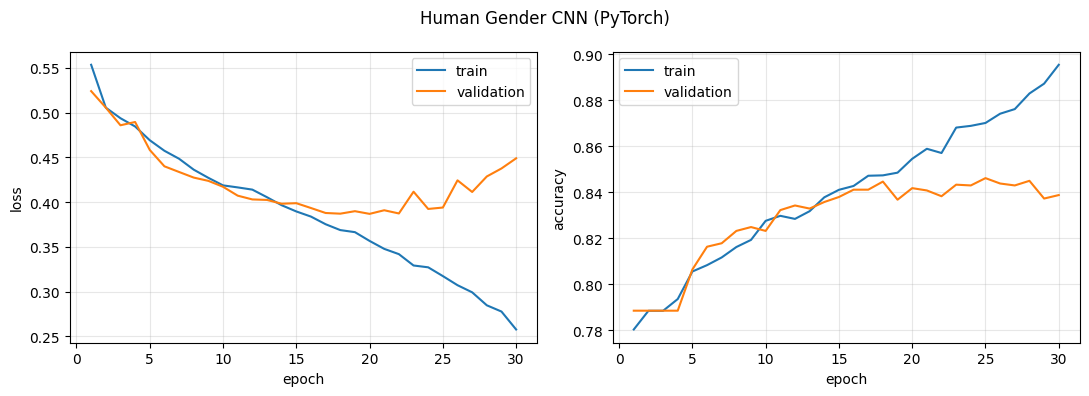

In [7]:
fig = plot_history(history, None if CHAY_THU else TEN, metric_label="accuracy",
                   title="Human Gender CNN (PyTorch)")
plt.show()

# (4) Evaluate trained model

Kết quả gốc: `Test loss: 0.4602`, `Test accuracy: 0.8264`.

In [8]:
score = evaluate(model, test_loader, loss_fn, accuracy)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.44891468785083966
Test accuracy: 0.8388069705093834


In [9]:
if not CHAY_THU:
    save_history(history, TEN)
    save_metrics(TEN, test_loss=score[0], test_metric=score[1], n_params=n_params,
                 epochs_ran=len(history["loss"]), best_epoch=None, train_time_s=train_time,
                 device=device_name(device), seed=0, baseline_toan_male=float(y_test.float().mean()))
    ghi_so_sanh(TEN, "2. CNN + MLP", "test_acc", keras=0.8264, pytorch=score[1],
                keras_params=4063570, pytorch_params=n_params, epochs_keras=30, epochs_pytorch=epochs,
                optimizer="Adam", lr=lr, batch=batch_size, device=device_name(device),
                train_time_s=train_time, seed=0,
                ghi_chu="Không chia 255 như gốc; đoán toàn male = 0.7885")

so_sanh.csv: 2_Human_Gender_CNN | test_acc Keras 0.8264 | PyTorch 0.8388 | chênh 0.0124


In [10]:
def int2gender(num):
    if num == 0:
        return 'female'
    else:
        return 'male'

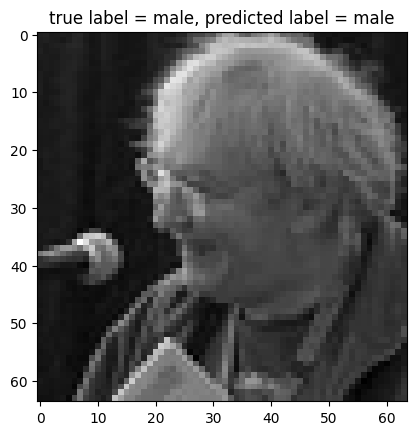

In [11]:
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]                  # (1, 64, 64)
test_label = int(y_test[random_test_index])

pred_label = predict(model, test_img.unsqueeze(0))
pred_label = int(pred_label.argmax(dim=1))

plt.imshow(test_img[0], cmap='gray')                  # gốc: test_img[:, :, 0]
plt.title('true label = %s, predicted label = %s' % (int2gender(test_label), int2gender(pred_label)))
plt.show()

## Phân tích thêm: accuracy từng lớp

Không có trong gốc. Vì dữ liệu lệch lớp (78,85% male), accuracy chung chưa nói được mô hình nhận ra female tốt đến đâu, nên tính thêm recall từng lớp và ma trận nhầm lẫn trên tập test. Không ảnh hưởng kết quả chính ở trên.

In [12]:
logits, nhan = predict(model, test_loader, return_targets=True)
du_doan = logits.argmax(dim=1)
for c in range(num_classes):
    m = nhan == c
    print("%-6s: %4d ảnh, recall %.4f" % (int2gender(c), int(m.sum()), float((du_doan[m] == c).float().mean())))
cm = torch.zeros(2, 2, dtype=torch.long)
for t, p in zip(nhan, du_doan):
    cm[t, p] += 1
print("Ma trận nhầm lẫn (hàng = thật, cột = dự đoán; 0 female, 1 male):")
print(cm.numpy())
den = x_test.flatten(1).amax(dim=1) == 0
print("Ảnh đen hoàn toàn: %d, mô hình đoán male cho %d ảnh trong số đó" % (int(den.sum()), int((du_doan[den] == 1).sum())))

female: 1262 ảnh, recall 0.3574
male  : 4706 ảnh, recall 0.9679
Ma trận nhầm lẫn (hàng = thật, cột = dự đoán; 0 female, 1 male):
[[ 451  811]
 [ 151 4555]]
Ảnh đen hoàn toàn: 662, mô hình đoán male cho 662 ảnh trong số đó
